# Super-resolución de imágenes con SRGAN (×2)
**Redes Neuronales y Deep Learning — Miniproyecto 3: Redes generativas**

Aplicación elegida: *aumentar la resolución de una imagen* (LR 64×64 → SR 128×128) con una GAN (SRGAN) en Keras/TensorFlow, entrenada con un dataset personalizado.

# 1. Configuración inicial

In [ ]:
# Importaciones globales
# ============================================================

# Sistema
import os
import time
import datetime
import numpy as np
import random

# Visualizacion
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

# Procesamiento de imagenes
from PIL import Image
import cv2

# TensorFlow / Keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model, Input
from tensorflow.keras.applications import VGG19
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.optimizers.schedules import PiecewiseConstantDecay
from tensorflow.keras.callbacks import TensorBoard
from tensorflow.keras.metrics import Mean
from tensorflow.keras.losses import BinaryCrossentropy, MeanSquaredError
from tensorflow.keras.preprocessing.image import load_img, img_to_array

# Metricas de evaluación
from tensorflow.image import psnr as tf_psnr
from tensorflow.image import ssim as tf_ssim


# Verificación del entorno
print("=" * 50)
print(f"TensorFlow version : {tf.__version__}")
print(f"NumPy version      : {np.__version__}")

gpu_devices = tf.config.list_physical_devices('GPU')
if gpu_devices:
    tf.config.experimental.set_memory_growth(gpu_devices[0], True)
    print(f"GPU detectada      : {gpu_devices[0].name}")
    print(f"Memory growth      : Activado")
else:
    print("ADVERTENCIA: No se detecto GPU.")

print("=" * 50)
print("Importaciones completadas correctamente.")

TensorFlow version : 2.21.0
NumPy version      : 2.4.6
GPU detectada      : /physical_device:GPU:0
Memory growth      : Activado
Importaciones completadas correctamente.


In [ ]:
# Montar Google Drive
# ============================================================

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Rutas del dataset
# ============================================================
BASE_PATH = '/content/drive/MyDrive/Dataset_Cats'
print(os.listdir(BASE_PATH))   # confirma los nombres: train / validation

TRAIN_HR = os.path.join(BASE_PATH, 'train')
VAL_HR   = os.path.join(BASE_PATH, 'val')   # ajusta si se llama distinto
# No hay pares LR reales: la LR se genera desde la HR en el pipeline
TRAIN_LR = TRAIN_HR
VAL_LR   = VAL_HR

['Val', 'Train']


In [ ]:
# Rutas del dataset
# ============================================================

BASE_PATH = '/content/drive/MyDrive/Dataset_Cats'

TRAIN_HR = os.path.join(BASE_PATH, 'Train', 'HR')
TRAIN_LR = os.path.join(BASE_PATH, 'Train', 'LR')
VAL_HR   = os.path.join(BASE_PATH, 'Val',   'HR')
VAL_LR   = os.path.join(BASE_PATH, 'Val',   'LR')

# Verificar que las carpetas existen y tienen el número correcto de imagenes
for split_name, hr_path, lr_path in [('Train', TRAIN_HR, TRAIN_LR),
                                      ('Val',   VAL_HR,   VAL_LR)]:
    hr_files = sorted(os.listdir(hr_path))
    lr_files = sorted(os.listdir(lr_path))
    print(f"\n{split_name}:")
    print(f"  HR: {len(hr_files)} imágenes - Ej: {hr_files[0]}")
    print(f"  LR: {len(lr_files)} imágenes - Ej: {lr_files[0]}")
    assert len(hr_files) == len(lr_files), "ERROR: El numero de imagenes HR y LR no coincide"

print("\nVerificación completada. Dataset listo.")


Train:
  HR: 69 imágenes - Ej: 10018.jpg
  LR: 69 imágenes - Ej: 10018.jpg

Val:
  HR: 30 imágenes - Ej: 1.jpg
  LR: 30 imágenes - Ej: 1.jpg

Verificación completada. Dataset listo.


## Descripción del dataset personalizado
- **Qué contiene:** *(COMPLETAR: tipo de imágenes, p. ej. paisajes, rostros, fotos propias…)*
- **Fuente / cómo se construyó:** *(COMPLETAR: cámara propia, web, otro dataset, pasos de limpieza…)*
- **Tamaño:** ver la celda siguiente (se calcula automáticamente).
- **Pares HR/LR:** HR = imagen original; LR = versión reducida ×2 con interpolación bicúbica (el pipeline la genera a partir de la HR).
- **División:** `train` para entrenar y `val` para validar (imágenes que el modelo nunca ve al entrenar).

In [ ]:
# Resumen automático del dataset: cantidad de imágenes y rango de resoluciones
def resumen_dataset(carpeta, nombre, muestras=30):
    archivos = sorted(os.listdir(carpeta))
    elegidos = random.sample(archivos, min(muestras, len(archivos)))
    anchos, altos = zip(*[Image.open(os.path.join(carpeta, f)).size for f in elegidos])
    print(f"{nombre:10s}: {len(archivos):4d} imágenes | ancho {min(anchos)}–{max(anchos)} px | alto {min(altos)}–{max(altos)} px (muestra de {len(elegidos)})")

resumen_dataset(TRAIN_HR, "Train HR")
resumen_dataset(TRAIN_LR, "Train LR")
resumen_dataset(VAL_HR,   "Val HR")
resumen_dataset(VAL_LR,   "Val LR")

Train HR  :   69 imágenes | ancho 128–128 px | alto 128–128 px (muestra de 30)
Train LR  :   69 imágenes | ancho 64–64 px | alto 64–64 px (muestra de 30)
Val HR    :   30 imágenes | ancho 128–128 px | alto 128–128 px (muestra de 30)
Val LR    :   30 imágenes | ancho 64–64 px | alto 64–64 px (muestra de 30)


In [ ]:
# Hiperparametros globales
# ============================================================

# Patches y escala
SCALE_FACTOR  = 2
HR_PATCH_SIZE = 128
LR_PATCH_SIZE = HR_PATCH_SIZE // SCALE_FACTOR  # 64

# Entrenamiento
BATCH_SIZE    = 8
EPOCHS        = 100

START_EPOCH = 48  # Cambiar este valor cada vez que se desconecte

LR_INITIAL    = 1e-4

# Arquitectura
NUM_RES_BLOCKS = 16
NUM_FILTERS    = 64

# Rutas de salida
LOG_DIR        = '/content/drive/MyDrive/srgan_logs'
CHECKPOINT_DIR = '/content/drive/MyDrive/srgan_checkpoints'

os.makedirs(LOG_DIR,        exist_ok=True)
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

print("Hiperparámetros configurados:")
print(f"  Escala          : {SCALE_FACTOR}×")
print(f"  HR patch        : {HR_PATCH_SIZE}×{HR_PATCH_SIZE}")
print(f"  LR patch        : {LR_PATCH_SIZE}×{LR_PATCH_SIZE}")
print(f"  Batch size      : {BATCH_SIZE}")
print(f"  Epochs          : {EPOCHS}")
print(f"  Res blocks      : {NUM_RES_BLOCKS}")
print(f"  Logs            : {LOG_DIR}")
print(f"  Checkpoints     : {CHECKPOINT_DIR}")

Hiperparámetros configurados:
  Escala          : 2×
  HR patch        : 128×128
  LR patch        : 64×64
  Batch size      : 8
  Epochs          : 100
  Res blocks      : 16
  Logs            : /content/drive/MyDrive/srgan_logs
  Checkpoints     : /content/drive/MyDrive/srgan_checkpoints


# 2. Pipeline
Cada imagen HR se redimensiona a 256×256, se toma un recorte aleatorio de 128×128 (parche HR) y se genera el parche LR de 64×64 con reducción bicúbica ×2. Se normaliza a [-1, 1] (rango de la salida `tanh` del generador) y se aplica *augmentation* sincronizada (flips) a ambos parches.

> Nota: `load_image_pair` recibe la ruta LR pero no la usa; el par LR se genera siempre desde la HR para garantizar alineación exacta entre ambas.

In [ ]:
# Pipeline de datos
# ============================================================

# Carga y generación de pares HR/LR desde imágenes HR
def load_image_pair(hr_path, lr_path):  # lr_path no se usa: la LR se deriva de la HR

    hr = tf.io.read_file(hr_path)
    hr = tf.image.decode_image(hr, channels=3, expand_animations=False)
    hr = tf.cast(hr, tf.float32)

    # Redimensionar HR a tamaño manejable
    hr = tf.image.resize(hr, [256, 256], method=tf.image.ResizeMethod.BICUBIC)

    # Generar LR con downscale ×2
    lr = tf.image.resize(hr, [128, 128], method=tf.image.ResizeMethod.BICUBIC)

    # Normalizar a [-1, 1]
    hr = hr / 127.5 - 1.0
    lr = lr / 127.5 - 1.0

    return lr, hr


# Crop aleatorio sincronizado HR/LR
def random_crop(lr, hr):

    # Crop aleatorio sobre HR
    hr_crop = tf.image.random_crop(hr, size=[HR_PATCH_SIZE, HR_PATCH_SIZE, 3])

    # Generar LR desde el crop HR con downscale ×2
    lr_crop = tf.image.resize(
        hr_crop,
        [LR_PATCH_SIZE, LR_PATCH_SIZE],
        method=tf.image.ResizeMethod.BICUBIC
    )

    hr_crop = tf.ensure_shape(hr_crop, [HR_PATCH_SIZE, HR_PATCH_SIZE, 3])
    lr_crop = tf.ensure_shape(lr_crop, [LR_PATCH_SIZE, LR_PATCH_SIZE, 3])

    return lr_crop, hr_crop


# Augmentation sincronizada
def augment(lr, hr):
    if tf.random.uniform(()) > 0.5:
        hr = tf.image.flip_left_right(hr)
        lr = tf.image.flip_left_right(lr)
    if tf.random.uniform(()) > 0.5:
        hr = tf.image.flip_up_down(hr)
        lr = tf.image.flip_up_down(lr)
    return lr, hr

# tf.data.Dataset de entrenamiento
# ============================================================

def build_dataset(hr_dir, lr_dir, batch_size, training=True):
    hr_files = sorted([os.path.join(hr_dir, f) for f in os.listdir(hr_dir)])
    lr_files = sorted([os.path.join(lr_dir, f) for f in os.listdir(lr_dir)])

    dataset = tf.data.Dataset.zip((
        tf.data.Dataset.from_tensor_slices(hr_files),
        tf.data.Dataset.from_tensor_slices(lr_files)
    ))

    dataset = dataset.map(
        lambda hr, lr: load_image_pair(hr, lr),
        num_parallel_calls=tf.data.AUTOTUNE
    )

    if training:
        dataset = dataset.map(random_crop, num_parallel_calls=tf.data.AUTOTUNE)
        dataset = dataset.map(augment,     num_parallel_calls=tf.data.AUTOTUNE)
        dataset = dataset.shuffle(buffer_size=100, reshuffle_each_iteration=True)
    else:
        # Validación: LR=64×64, HR=128×128
        dataset = dataset.map(
            lambda lr, hr: (
                tf.ensure_shape(
                    tf.image.resize(lr, [LR_PATCH_SIZE, LR_PATCH_SIZE]),
                    [LR_PATCH_SIZE, LR_PATCH_SIZE, 3]
                ),
                tf.ensure_shape(
                    tf.image.resize(hr, [HR_PATCH_SIZE, HR_PATCH_SIZE]),
                    [HR_PATCH_SIZE, HR_PATCH_SIZE, 3]
                )
            ),
            num_parallel_calls=tf.data.AUTOTUNE
        )

    dataset = dataset.batch(batch_size, drop_remainder=True)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


# Reconstruir ambos datasets
train_dataset = build_dataset(TRAIN_HR, TRAIN_LR, BATCH_SIZE, training=True)
val_dataset   = build_dataset(VAL_HR,   VAL_LR,   batch_size=1, training=False)

print("Datasets reconstruidos correctamente.")

# Verificar shapes
sample_lr, sample_hr = next(iter(train_dataset))
print(f"Batch LR shape : {sample_lr.shape}")   # esperado: (8, 64, 64, 3)
print(f"Batch HR shape : {sample_hr.shape}")   # esperado: (8, 128, 128, 3)
print("Dataset construido correctamente.")

Datasets reconstruidos correctamente.
Batch LR shape : (8, 64, 64, 3)
Batch HR shape : (8, 128, 128, 3)
Dataset construido correctamente.


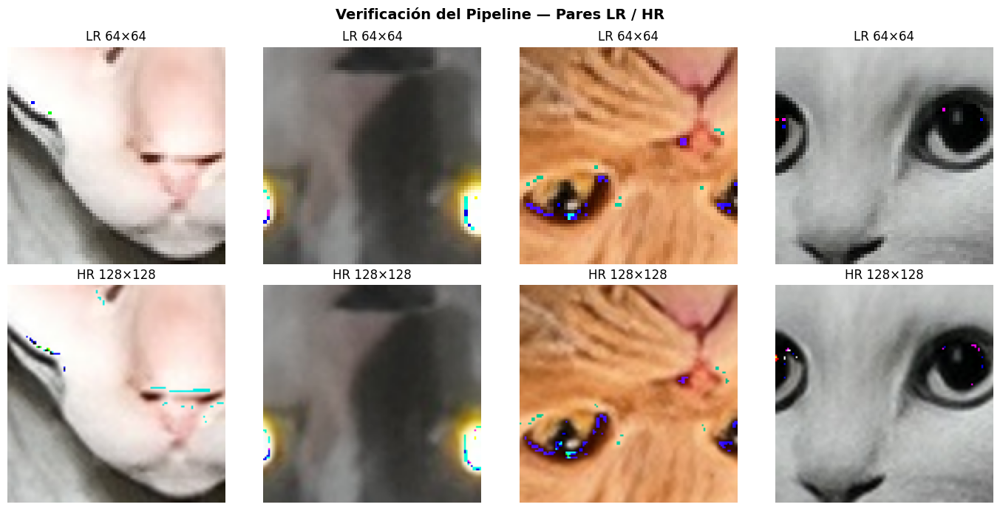

In [ ]:
# Verificación del pipeline
# ============================================================

def denormalize(img):
    return ((img + 1.0) * 127.5).numpy().astype(np.uint8)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
fig.suptitle('Verificación del Pipeline — Pares LR / HR', fontsize=14, fontweight='bold')

for i in range(4):
    axes[0, i].imshow(denormalize(sample_lr[i]))
    axes[0, i].set_title(f'LR {LR_PATCH_SIZE}×{LR_PATCH_SIZE}')
    axes[0, i].axis('off')

    axes[1, i].imshow(denormalize(sample_hr[i]))
    axes[1, i].set_title(f'HR {HR_PATCH_SIZE}×{HR_PATCH_SIZE}')
    axes[1, i].axis('off')

plt.tight_layout()
plt.show()

# 3. SRGAN
**Generador:** conv 9×9 → 16 bloques residuales (Conv-BN-PReLU-Conv-BN + skip) → conv + skip global → un bloque de *upsampling* (Conv + PixelShuffle) → conv 9×9 con `tanh`.
**Discriminador:** 8 bloques convolucionales (Conv-BN-LeakyReLU, canales 64→512, 4 con stride 2) → Dense(1024) → Dense(1, sigmoid): decide si un parche 128×128 es real (HR) o generado (SR).

In [ ]:
# Arquitectura SRGAN
# ============================================================

# Bloque Residual (ResBlock)
def residual_block(x, filters=64):

    skip = x
    x = layers.Conv2D(filters, kernel_size=3, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization(momentum=0.8)(x)
    x = layers.PReLU(shared_axes=[1, 2])(x)
    x = layers.Conv2D(filters, kernel_size=3, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization(momentum=0.8)(x)
    x = layers.Add()([skip, x])
    return x

# Capa personalizada para PixelShuffle
class PixelShuffle(layers.Layer):
    def __init__(self, scale=2, **kwargs):
        super().__init__(**kwargs)
        self.scale = scale

    def call(self, x):
        return tf.nn.depth_to_space(x, block_size=self.scale)


# Bloque de Upsampling ×2
def upsample_block(x, filters=256):
    x = layers.Conv2D(filters * 4, kernel_size=3, padding='same')(x)
    x = PixelShuffle(scale=2)(x)
    x = layers.PReLU(shared_axes=[1, 2])(x)
    return x

# Generador
def build_generator(num_res_blocks=NUM_RES_BLOCKS, num_filters=NUM_FILTERS,
                    input_shape=(LR_PATCH_SIZE, LR_PATCH_SIZE, 3)):

    inputs = Input(shape=input_shape, name='lr_input')

    # Convolucion inicial
    x = layers.Conv2D(num_filters, kernel_size=9, padding='same', name='initial_conv')(inputs)
    x = layers.PReLU(shared_axes=[1, 2], name='initial_prelu')(x)
    skip = x  # Guardar para la conexion residual global

    # Bloques residuales
    for i in range(num_res_blocks):
        x = residual_block(x, filters=num_filters)

    # Convolucion post-residual + conexion residual global
    x = layers.Conv2D(num_filters, kernel_size=3, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization(momentum=0.8)(x)
    x = layers.Add()([skip, x])

    # Upsampling ×2 (LR 64×64 - SR 128×128)
    x = upsample_block(x, filters=num_filters)

    # Convolucion final - salida en [-1, 1] con tanh
    outputs = layers.Conv2D(3, kernel_size=9, padding='same',
                            activation='tanh', name='sr_output')(x)

    return Model(inputs, outputs, name='Generator')


# Bloque discriminador
def discriminator_block(x, filters, strides=1, batch_norm=True):

    x = layers.Conv2D(filters, kernel_size=3, strides=strides,
                      padding='same', use_bias=False)(x)
    if batch_norm:
        x = layers.BatchNormalization(momentum=0.8)(x)
    x = layers.LeakyReLU(alpha=0.2)(x)
    return x


# Discriminador
def build_discriminator(num_filters=NUM_FILTERS):

    inputs = Input(shape=(HR_PATCH_SIZE, HR_PATCH_SIZE, 3), name='hr_input')

    # Primera capa sin BatchNorm
    x = discriminator_block(inputs, num_filters,     strides=1, batch_norm=False)
    x = discriminator_block(x,      num_filters,     strides=2)
    x = discriminator_block(x,      num_filters * 2, strides=1)
    x = discriminator_block(x,      num_filters * 2, strides=2)
    x = discriminator_block(x,      num_filters * 4, strides=1)
    x = discriminator_block(x,      num_filters * 4, strides=2)
    x = discriminator_block(x,      num_filters * 8, strides=1)
    x = discriminator_block(x,      num_filters * 8, strides=2)

    # Clasificador final
    x = layers.Flatten()(x)
    x = layers.Dense(1024)(x)
    x = layers.LeakyReLU(alpha=0.2)(x)
    outputs = layers.Dense(1, activation='sigmoid', name='validity')(x)

    return Model(inputs, outputs, name='Discriminator')

In [ ]:
# Instanciar y verificar modelos
generator     = build_generator()
discriminator = build_discriminator()

print("=" * 50)
print("GENERADOR")
print("=" * 50)
generator.summary()

print("\n" + "=" * 50)
print("DISCRIMINADOR")
print("=" * 50)
discriminator.summary()

# Verificación con datos reales del pipeline
test_lr  = sample_lr[:1]                     # 1 imagen LR: [1, 64, 64, 3]
test_sr  = generator(test_lr, training=False) # Salida SR:   [1, 128, 128, 3]
test_d   = discriminator(test_sr, training=False)

print(f"Entrada LR      : {test_lr.shape}")
print(f"Salida SR       : {test_sr.shape}")   # esperado: (1, 128, 128, 3)
print(f"Salida Disc     : {test_d.shape}")    # esperado: (1, 1)
print(f"Rango SR        : [{test_sr.numpy().min():.3f}, {test_sr.numpy().max():.3f}]")
print("\nArquitectura verificada correctamente.")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/activations/leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_slope` instead.
  warnings.warn(


GENERADOR


Model: "Generator"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ lr_input            │ (None, 64, 64, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ initial_conv        │ (None, 64, 64,    │     15,616 │ lr_input[0][0]    │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ initial_prelu       │ (None, 64, 64,    │         64 │ initial_conv[0][… │
│ (PReLU)             │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 64, 64,    │     36,864 │ initial_prelu[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 64, 64,    │        256 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu (PReLU)     │ (None, 64, 64,    │         64 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 64, 64,    │     36,864 │ p_re_lu[0][0]     │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 64, 64,    │          0 │ initial_prelu[0]… │
│                     │ 64)               │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 64, 64,    │     36,864 │ add[0][0]         │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_1 (PReLU)   │ (None, 64, 64,    │         64 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 64, 64,    │     36,864 │ p_re_lu_1[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 64, 64,    │          0 │ add[0][0],        │
│                     │ 64)               │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 64, 64,    │     36,864 │ add_1[0][0]       │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_4[0][0]  

 Total params: 1,404,995 (5.36 MB)

 Trainable params: 1,400,771 (5.34 MB)

... (4 outputs left out)

 Total params: 38,247,361 (145.90 MB)

 Trainable params: 38,243,649 (145.89 MB)

 Non-trainable params: 3,712 (14.50 KB)

Entrada LR      : (1, 64, 64, 3)
Salida SR       : (1, 128, 128, 3)
Salida Disc     : (1, 1)
Rango SR        : [-1.000, 1.000]

Arquitectura verificada correctamente.


# 4. Funciones de pérdida
- **Perceptual (contenido):** MSE entre las *feature maps* de VGG19 (`block3_conv3`, pesos ImageNet congelados) de la imagen real y la generada.
- **Adversarial:** el generador intenta que el discriminador clasifique sus imágenes como reales.
- **Discriminador:** BCE con *label smoothing* (real = 0.9) para estabilizar el entrenamiento.
- **Total del generador:** `1.0 · perceptual + 1e-4 · adversarial`.

In [ ]:
# Funciones de pérdida
# ============================================================

# Red VGG19 para pérdida perceptual
def build_vgg():

    vgg = VGG19(weights='imagenet', include_top=False, input_shape=(HR_PATCH_SIZE, HR_PATCH_SIZE, 3))
    vgg.trainable = False
    return Model(vgg.input, vgg.get_layer('block3_conv3').output, name='VGG_features')

vgg_feature_extractor = build_vgg()
print(f"VGG feature extractor: {vgg_feature_extractor.output_shape}")

# Pérdida de contenido (Perceptual Loss)
def content_loss(hr, sr):

    # Desnormalizar de [-1, 1] a [0, 255]
    hr_vgg = (hr + 1.0) * 127.5
    sr_vgg = (sr + 1.0) * 127.5

    # Preprocesamiento estándar VGG19
    hr_vgg = tf.keras.applications.vgg19.preprocess_input(hr_vgg)
    sr_vgg = tf.keras.applications.vgg19.preprocess_input(sr_vgg)

    # Extraer features
    hr_features = vgg_feature_extractor(hr_vgg, training=False)
    sr_features = vgg_feature_extractor(sr_vgg, training=False)

    # MSE en espacio de features
    return tf.reduce_mean(tf.square(hr_features - sr_features))


# Pérdida adversarial del Generador
def generator_adversarial_loss(fake_output):

    bce = BinaryCrossentropy(from_logits=False)
    return bce(tf.ones_like(fake_output), fake_output)


# Pérdida del Discriminador con Label Smoothing
def discriminator_loss(real_output, fake_output):
    bce = BinaryCrossentropy(from_logits=False)
    real_loss = bce(tf.ones_like(real_output) * 0.9, real_output)  # 1.0 -> 0.9
    fake_loss = bce(tf.zeros_like(fake_output),      fake_output)
    return real_loss + fake_loss


# Pérdida total del Generador
# Combinación ponderada de pérdida perceptual + adversarial
LAMBDA_CONTENT     = 1.0    # Peso pérdida perceptual
LAMBDA_ADVERSARIAL = 1e-4   # Peso pérdida adversarial (estándar SRGAN)

def generator_total_loss(hr, sr, fake_output):

    perc_loss = content_loss(hr, sr)
    adv_loss  = generator_adversarial_loss(fake_output)
    total     = LAMBDA_CONTENT * perc_loss + LAMBDA_ADVERSARIAL * adv_loss
    return total, perc_loss, adv_loss

80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
VGG feature extractor: (None, 32, 32, 256)


In [ ]:
# Verificación de las pérdidas con datos reales
test_hr = sample_hr[:1]
test_lr = sample_lr[:1]
test_sr = generator(test_lr, training=False)

fake_out  = discriminator(test_sr,  training=False)
real_out  = discriminator(test_hr,  training=False)

total_g, perc, adv = generator_total_loss(test_hr, test_sr, fake_out)
disc_l              = discriminator_loss(real_out, fake_out)

print("Verificación de pérdidas:")
print(f"  Pérdida perceptual  : {perc.numpy():.4f}")
print(f"  Pérdida adversarial : {adv.numpy():.4f}")
print(f"  Pérdida total Gen   : {total_g.numpy():.4f}")
print(f"  Pérdida Disc        : {disc_l.numpy():.4f}")
print("\nFunciones de pérdida verificadas correctamente.")

Verificación de pérdidas:
  Pérdida perceptual  : 2294951.0000
  Pérdida adversarial : 0.7048
  Pérdida total Gen   : 2294951.0000
  Pérdida Disc        : 1.3801

Funciones de pérdida verificadas correctamente.


# 5. Entrenamiento
Adam (G: 1e-4, D: 5e-5), batch 8, 100 épocas. Cada época: entrenamiento en parches + validación con PSNR/SSIM. Se guarda el mejor modelo por PSNR y un checkpoint cada 10 épocas; todo se registra en TensorBoard.

In [ ]:
# Optimizadores y TensorBoard
# ============================================================

# Optimizadores
generator_optimizer     = Adam(learning_rate=LR_INITIAL, beta_1=0.9)
discriminator_optimizer = Adam(learning_rate=5e-5, beta_1=0.9)

# TensorBoard
log_dir    = os.path.join(LOG_DIR, datetime.datetime.now().strftime("%Y%m%d-%H%M%S"))
tb_writer  = tf.summary.create_file_writer(log_dir)
print(f"TensorBoard logs → {log_dir}")

# Métricas acumuladas por época
metric_g_total   = Mean(name='g_total_loss')
metric_g_perc    = Mean(name='g_perceptual_loss')
metric_g_adv     = Mean(name='g_adversarial_loss')
metric_d         = Mean(name='d_loss')
metric_psnr      = Mean(name='psnr')
metric_ssim      = Mean(name='ssim')

TensorBoard logs → /content/drive/MyDrive/srgan_logs/20261121-210143


In [ ]:
# Paso de entrenamiento (un batch)
# ============================================================
@tf.function
def train_step(lr_imgs, hr_imgs):
    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:

        # Forward pass generador
        sr_imgs = generator(lr_imgs, training=True)

        # Forward pass discriminador
        real_output = discriminator(hr_imgs, training=True)
        fake_output = discriminator(sr_imgs, training=True)

        # Calcular pérdidas
        g_total, g_perc, g_adv = generator_total_loss(hr_imgs, sr_imgs, fake_output)
        d_loss                  = discriminator_loss(real_output, fake_output)

    # Gradientes y actualización
    gen_grads  = gen_tape.gradient(g_total,  generator.trainable_variables)
    disc_grads = disc_tape.gradient(d_loss,  discriminator.trainable_variables)

    generator_optimizer.apply_gradients(
        zip(gen_grads,  generator.trainable_variables)
    )
    discriminator_optimizer.apply_gradients(
        zip(disc_grads, discriminator.trainable_variables)
    )

    return g_total, g_perc, g_adv, d_loss

# Paso de validación (una imagen completa)
# ============================================================
@tf.function
def val_step(lr_img, hr_img):
    sr_img = generator(lr_img, training=False)

    # PSNR y SSIM en rango [0, 1]
    hr_01 = (hr_img + 1.0) / 2.0
    sr_01 = (sr_img + 1.0) / 2.0

    psnr = tf_psnr(hr_01, sr_01, max_val=1.0)
    ssim = tf_ssim(hr_01, sr_01, max_val=1.0)

    return sr_img, psnr, ssim

In [ ]:
# Función de visualización para TensorBoard
# ============================================================
def log_images_to_tensorboard(writer, lr, sr, hr, step, num_images=4):
    """
    Registra pares LR / SR / HR en TensorBoard como imágenes.
    Convierte de [-1,1] a [0,1] para visualización.
    """
    lr_vis = (lr[:num_images] + 1.0) / 2.0
    sr_vis = (sr[:num_images] + 1.0) / 2.0
    hr_vis = (hr[:num_images] + 1.0) / 2.0

    # Redimensionar LR al tamaño HR para comparación visual
    lr_up = tf.image.resize(lr_vis, [HR_PATCH_SIZE, HR_PATCH_SIZE],
                            method=tf.image.ResizeMethod.BICUBIC)

    with writer.as_default():
        tf.summary.image("1_LR_bicubic",  lr_up, step=step, max_outputs=num_images)
        tf.summary.image("2_SR_generada", sr_vis, step=step, max_outputs=num_images)
        tf.summary.image("3_HR_real",     hr_vis, step=step, max_outputs=num_images)

In [ ]:
# Cargar pesos para reanudar (solo si existe un checkpoint y START_EPOCH > 1)
best_gen_path  = os.path.join(CHECKPOINT_DIR, 'best_generator.weights.h5')
best_disc_path = os.path.join(CHECKPOINT_DIR, 'best_discriminator.weights.h5')
reanudando = START_EPOCH > 1 and os.path.exists(best_gen_path) and os.path.exists(best_disc_path)

if reanudando:
    generator.load_weights(best_gen_path)
    discriminator.load_weights(best_disc_path)
    print(f"Pesos cargados. Reanudando desde época {START_EPOCH}...")
    # PSNR de partida = el del modelo cargado, para no sobrescribir un mejor checkpoint
    _p = []
    for lr_v, hr_v in val_dataset:
        _, p_, _ = val_step(lr_v, hr_v)
        _p.append(p_.numpy().mean())
    best_psnr = float(np.mean(_p))
    print(f"PSNR de partida: {best_psnr:.2f} dB")
else:
    START_EPOCH = 1
    best_psnr = 0.0
    print("Entrenamiento desde cero (época 1).")

Pesos cargados. Reanudando desde época 48...
PSNR de partida: 22.25 dB


In [ ]:
# Bucle de entrenamiento principal
# ============================================================
print("Iniciando entrenamiento SRGAN...")
print(f"  Épocas        : {EPOCHS}")
print(f"  Batch size    : {BATCH_SIZE}")
print(f"  Log dir       : {log_dir}\n")

history = {k: [] for k in ['epoch', 'g_total', 'g_perc', 'g_adv', 'd_loss', 'psnr', 'ssim']}
for epoch in range(START_EPOCH, EPOCHS + 1):
    start_time = time.time()

    # Resetear métricas
    metric_g_total.reset_state()
    metric_g_perc.reset_state()
    metric_g_adv.reset_state()
    metric_d.reset_state()
    metric_psnr.reset_state()
    metric_ssim.reset_state()

    # Entrenamiento
    for lr_batch, hr_batch in train_dataset:
        g_total, g_perc, g_adv, d_loss = train_step(lr_batch, hr_batch)
        metric_g_total.update_state(g_total)
        metric_g_perc.update_state(g_perc)
        metric_g_adv.update_state(g_adv)
        metric_d.update_state(d_loss)

    # Validación
    for lr_val, hr_val in val_dataset:
        sr_val, psnr, ssim = val_step(lr_val, hr_val)
        metric_psnr.update_state(psnr)
        metric_ssim.update_state(ssim)

    # Métricas de la época
    g_total_val = metric_g_total.result()
    g_perc_val  = metric_g_perc.result()
    g_adv_val   = metric_g_adv.result()
    d_val       = metric_d.result()
    psnr_val    = metric_psnr.result()
    ssim_val    = metric_ssim.result()
    elapsed     = time.time() - start_time

    # Historial de esta sesión (para graficar curvas)
    for k, v in zip(history.keys(), [epoch, g_total_val, g_perc_val, g_adv_val, d_val, psnr_val, ssim_val]):
        history[k].append(float(v))

    # Logging TensorBoard
    with tb_writer.as_default():
        tf.summary.scalar('Loss/Generator_Total',   g_total_val, step=epoch)
        tf.summary.scalar('Loss/Generator_Percept', g_perc_val,  step=epoch)
        tf.summary.scalar('Loss/Generator_Advers',  g_adv_val,   step=epoch)
        tf.summary.scalar('Loss/Discriminator',     d_val,       step=epoch)
        tf.summary.scalar('Metrics/PSNR',           psnr_val,    step=epoch)
        tf.summary.scalar('Metrics/SSIM',           ssim_val,    step=epoch)

    # Imágenes en TensorBoard cada 10 épocas
    if epoch % 10 == 0:
        sample_lr_val, sample_hr_val = next(iter(val_dataset))
        sample_sr_val = generator(sample_lr_val, training=False)
        log_images_to_tensorboard(
            tb_writer, sample_lr_val, sample_sr_val, sample_hr_val, step=epoch
        )

    # Guardar mejor modelo
    if psnr_val > best_psnr:
        best_psnr = psnr_val
        generator.save_weights(
            os.path.join(CHECKPOINT_DIR, 'best_generator.weights.h5')
        )
        discriminator.save_weights(
            os.path.join(CHECKPOINT_DIR, 'best_discriminator.weights.h5')
        )

    # Checkpoint cada 10 épocas
    if epoch % 10 == 0:
        generator.save_weights(
            os.path.join(CHECKPOINT_DIR, f'generator_epoch{epoch}.weights.h5')
        )

    # Consola
    print(f"Época {epoch:03d}/{EPOCHS} | "
          f"G: {g_total_val:.2f} "
          f"(perc: {g_perc_val:.2f}, adv: {g_adv_val:.4f}) | "
          f"D: {d_val:.4f} | "
          f"PSNR: {psnr_val:.2f} dB | "
          f"SSIM: {ssim_val:.4f} | "
          f"⏱ {elapsed:.1f}s")

print(f"\nEntrenamiento completado. Mejor PSNR: {best_psnr:.2f} dB")

Iniciando entrenamiento SRGAN...
  Épocas        : 100
  Batch size    : 8
  Log dir       : /content/drive/MyDrive/srgan_logs/20261121-210143

Época 048/100 | G: 8352.75 (perc: 8352.75, adv: 16.0257) | D: 0.6169 | PSNR: 21.89 dB | SSIM: 0.5292 | ⏱ 37.4s
Época 049/100 | G: 6806.13 (perc: 6806.13, adv: 19.0907) | D: 0.4444 | PSNR: 22.01 dB | SSIM: 0.5342 | ⏱ 3.5s
Época 050/100 | G: 6786.34 (perc: 6786.33, adv: 17.3207) | D: 0.4086 | PSNR: 22.23 dB | SSIM: 0.5547 | ⏱ 3.1s
Época 051/100 | G: 6346.50 (perc: 6346.50, adv: 16.7753) | D: 0.3883 | PSNR: 22.25 dB | SSIM: 0.5538 | ⏱ 3.1s
Época 052/100 | G: 5919.80 (perc: 5919.80, adv: 18.0481) | D: 0.3549 | PSNR: 21.86 dB | SSIM: 0.5336 | ⏱ 3.2s
Época 053/100 | G: 6323.36 (perc: 6323.35, adv: 15.6630) | D: 0.3707 | PSNR: 22.44 dB | SSIM: 0.5650 | ⏱ 5.8s
Época 054/100 | G: 5921.01 (perc: 5921.01, adv: 16.6297) | D: 0.3625 | PSNR: 22.38 dB | SSIM: 0.5552 | ⏱ 3.1s
Época 055/100 | G: 5689.34 (perc: 5689.34, adv: 16.8294) | D: 0.3586 | PSNR: 21.97 dB

In [ ]:
# Lanzar TensorBoard
%load_ext tensorboard
%tensorboard --logdir {LOG_DIR}

<IPython.core.display.Javascript object>

# 6. Validación
Se evalúa el mejor generador (mayor PSNR) sobre todo el set de validación con **PSNR** y **SSIM**, comparación visual LR | SR | HR y, además, contra un *baseline* de interpolación bicúbica.

In [ ]:
# Validación final
# ============================================================

# Cargar los mejores pesos guardados
generator.load_weights(os.path.join(CHECKPOINT_DIR, 'best_generator.weights.h5'))
print("Mejores pesos cargados.")

# Evaluación completa sobre el set de validación
print("Evaluando sobre set de validación completo...\n")

psnr_scores = []
ssim_scores = []

for lr_val, hr_val in val_dataset:
    sr_val, psnr, ssim = val_step(lr_val, hr_val)
    psnr_scores.append(psnr.numpy().mean())
    ssim_scores.append(ssim.numpy().mean())

psnr_scores = np.array(psnr_scores)
ssim_scores = np.array(ssim_scores)

print("=" * 45)
print(f"  PSNR  — Media : {psnr_scores.mean():.4f} dB")
print(f"  PSNR  — Std   : {psnr_scores.std():.4f} dB")
print(f"  PSNR  — Min   : {psnr_scores.min():.4f} dB")
print(f"  PSNR  — Max   : {psnr_scores.max():.4f} dB")
print("-" * 45)
print(f"  SSIM  — Media : {ssim_scores.mean():.4f}")
print(f"  SSIM  — Std   : {ssim_scores.std():.4f}")
print(f"  SSIM  — Min   : {ssim_scores.min():.4f}")
print(f"  SSIM  — Max   : {ssim_scores.max():.4f}")
print("=" * 45)

Mejores pesos cargados.
Evaluando sobre set de validación completo...

  PSNR  — Media : 22.8015 dB
  PSNR  — Std   : 1.9455 dB
  PSNR  — Min   : 17.2603 dB
  PSNR  — Max   : 27.2458 dB
---------------------------------------------
  SSIM  — Media : 0.5780
  SSIM  — Std   : 0.0782
  SSIM  — Min   : 0.4022
  SSIM  — Max   : 0.6982


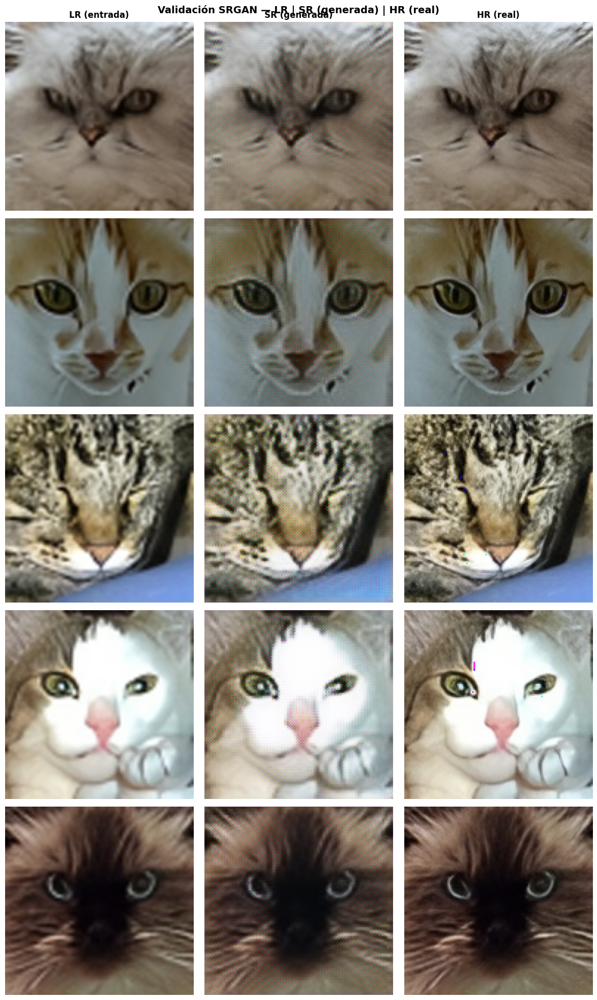

Figura guardada en CHECKPOINT_DIR.


In [ ]:
# Comparación visual: LR / SR / HR
def visualize_results(val_dataset, generator, num_samples=5):
    fig, axes = plt.subplots(num_samples, 3, figsize=(12, num_samples * 4))
    fig.suptitle('Validación SRGAN — LR | SR (generada) | HR (real)',
                 fontsize=14, fontweight='bold')

    col_titles = ['LR (entrada)', 'SR (generada)', 'HR (real)']
    for ax, title in zip(axes[0], col_titles):
        ax.set_title(title, fontsize=12, fontweight='bold')

    for i, (lr_val, hr_val) in enumerate(val_dataset.take(num_samples)):
        sr_val = generator(lr_val, training=False)

        lr_img = ((lr_val[0].numpy() + 1.0) * 127.5).astype(np.uint8)
        sr_img = ((sr_val[0].numpy() + 1.0) * 127.5).astype(np.uint8)
        hr_img = ((hr_val[0].numpy() + 1.0) * 127.5).astype(np.uint8)

        # Redimensionar LR para visualización
        lr_up = cv2.resize(lr_img, (HR_PATCH_SIZE, HR_PATCH_SIZE),
                           interpolation=cv2.INTER_CUBIC)

        # Calcular métricas por imagen
        hr_01 = hr_val / 2.0 + 0.5
        sr_01 = sr_val / 2.0 + 0.5
        p = tf_psnr(hr_01, sr_01, max_val=1.0).numpy().mean()
        s = tf_ssim(hr_01, sr_01, max_val=1.0).numpy().mean()

        axes[i, 0].imshow(lr_up)
        axes[i, 0].set_ylabel(f'Muestra {i+1}', fontsize=10)
        axes[i, 0].axis('off')

        axes[i, 1].imshow(sr_img)
        axes[i, 1].set_xlabel(f'PSNR: {p:.2f} dB | SSIM: {s:.4f}', fontsize=9)
        axes[i, 1].axis('off')

        axes[i, 2].imshow(hr_img)
        axes[i, 2].axis('off')

    plt.tight_layout()
    plt.savefig(os.path.join(CHECKPOINT_DIR, 'validacion_final.png'),
                dpi=150, bbox_inches='tight')
    plt.show()
    print("Figura guardada en CHECKPOINT_DIR.")

visualize_results(val_dataset, generator, num_samples=5)

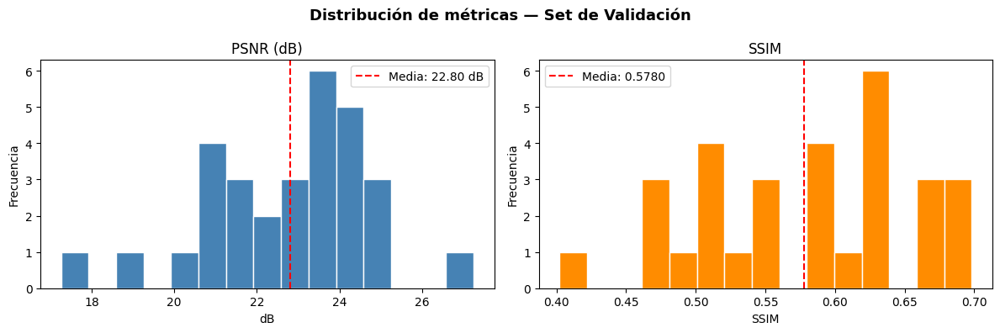

Gráfica guardada en CHECKPOINT_DIR.


In [ ]:
# Gráfica de métricas finales
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle('Distribución de métricas — Set de Validación', fontsize=13, fontweight='bold')

# PSNR
axes[0].hist(psnr_scores, bins=15, color='steelblue', edgecolor='white')
axes[0].axvline(psnr_scores.mean(), color='red', linestyle='--',
                label=f'Media: {psnr_scores.mean():.2f} dB')
axes[0].set_title('PSNR (dB)')
axes[0].set_xlabel('dB')
axes[0].set_ylabel('Frecuencia')
axes[0].legend()

# SSIM
axes[1].hist(ssim_scores, bins=15, color='darkorange', edgecolor='white')
axes[1].axvline(ssim_scores.mean(), color='red', linestyle='--',
                label=f'Media: {ssim_scores.mean():.4f}')
axes[1].set_title('SSIM')
axes[1].set_xlabel('SSIM')
axes[1].set_ylabel('Frecuencia')
axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(CHECKPOINT_DIR, 'metricas_distribucion.png'),
            dpi=150, bbox_inches='tight')
plt.show()
print("Gráfica guardada en CHECKPOINT_DIR.")

In [ ]:
# Comparación contra el baseline bicúbico (sin red neuronal)
psnr_bic, ssim_bic, psnr_sr, ssim_sr = [], [], [], []

for lr_val, hr_val in val_dataset:
    sr_val  = generator(lr_val, training=False)
    bic_val = tf.image.resize(lr_val, [HR_PATCH_SIZE, HR_PATCH_SIZE],
                              method=tf.image.ResizeMethod.BICUBIC)
    bic_val = tf.clip_by_value(bic_val, -1.0, 1.0)

    hr01, sr01, bic01 = (hr_val + 1) / 2, (sr_val + 1) / 2, (bic_val + 1) / 2
    psnr_sr.append(tf_psnr(hr01, sr01, max_val=1.0).numpy().mean())
    ssim_sr.append(tf_ssim(hr01, sr01, max_val=1.0).numpy().mean())
    psnr_bic.append(tf_psnr(hr01, bic01, max_val=1.0).numpy().mean())
    ssim_bic.append(tf_ssim(hr01, bic01, max_val=1.0).numpy().mean())

print("=" * 52)
print(f"{'Método':<12}{'PSNR (dB)':>14}{'SSIM':>14}")
print("-" * 52)
print(f"{'Bicúbica':<12}{np.mean(psnr_bic):>14.2f}{np.mean(ssim_bic):>14.4f}")
print(f"{'SRGAN':<12}{np.mean(psnr_sr):>14.2f}{np.mean(ssim_sr):>14.4f}")
print("=" * 52)
print(f"Diferencia SRGAN - Bicúbica: {np.mean(psnr_sr)-np.mean(psnr_bic):+.2f} dB | {np.mean(ssim_sr)-np.mean(ssim_bic):+.4f} SSIM")

Método           PSNR (dB)          SSIM
----------------------------------------------------
Bicúbica             31.77        0.9385
SRGAN                22.80        0.5780
Diferencia SRGAN - Bicúbica: -8.97 dB | -0.3606 SSIM


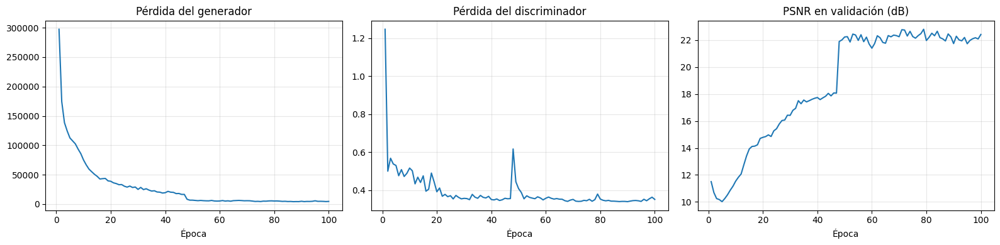

In [ ]:
# Curvas de entrenamiento completas (lee los logs de TensorBoard de TODAS las sesiones/reanudaciones)
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

def cargar_escalar(log_root, tag):
    puntos = {}
    for run in sorted(os.listdir(log_root)):
        ruta = os.path.join(log_root, run)
        if not os.path.isdir(ruta):
            continue
        ea = EventAccumulator(ruta, size_guidance={'tensors': 0, 'scalars': 0})
        ea.Reload()
        tags = ea.Tags()
        if tag in tags.get('scalars', []):
            for e in ea.Scalars(tag):
                puntos[e.step] = e.value
        elif tag in tags.get('tensors', []):
            for e in ea.Tensors(tag):
                puntos[e.step] = float(tf.make_ndarray(e.tensor_proto))
    pasos = sorted(puntos)
    return pasos, [puntos[p] for p in pasos]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for tag, ax, titulo in [('Loss/Generator_Total', axes[0], 'Pérdida del generador'),
                        ('Loss/Discriminator',   axes[1], 'Pérdida del discriminador'),
                        ('Metrics/PSNR',         axes[2], 'PSNR en validación (dB)')]:
    x, y = cargar_escalar(LOG_DIR, tag)
    ax.plot(x, y)
    ax.set_title(titulo); ax.set_xlabel('Época'); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(CHECKPOINT_DIR, 'curvas_entrenamiento.png'), dpi=150, bbox_inches='tight')
plt.show()

## Prueba con una imagen completa (cualquier tamaño)
El generador es totalmente convolucional, por lo que se reconstruye con entrada `(None, None, 3)` y se le copian los pesos entrenados. Así se puede aumentar la resolución de una imagen real de baja resolución, no solo parches de 64×64.

Saving prueba_final.jpeg to prueba_final (2).jpeg
Imagen de entrada: 64×64 px
Resultado: 128×128 px


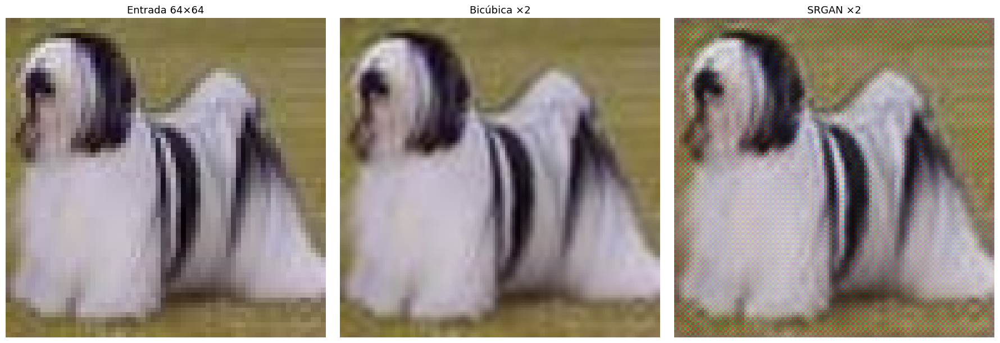

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Probar una imagen propia: subir, escalar ×2 y descargar el resultado
from google.colab import files

# 1. Generador de tamaño libre con los mejores pesos entrenados
generator_full = build_generator(input_shape=(None, None, 3))
generator_full.load_weights(os.path.join(CHECKPOINT_DIR, 'best_generator.weights.h5'))

# 2. Subir la imagen
subidas = files.upload()
nombre = list(subidas.keys())[0]
img = Image.open(nombre).convert('RGB')      # convierte PNG con transparencia a RGB
print(f"Imagen de entrada: {img.size[0]}×{img.size[1]} px")

# Limitar el tamaño para no agotar la memoria de la GPU
MAX_LADO = 512
if max(img.size) > MAX_LADO:
    esc = MAX_LADO / max(img.size)
    img = img.resize((int(img.size[0] * esc), int(img.size[1] * esc)), Image.BICUBIC)
    print(f"Reducida a {img.size[0]}×{img.size[1]} px")

# 3. Escalar
entrada = np.array(img).astype(np.float32) / 127.5 - 1.0
sr = generator_full(entrada[None, ...], training=False)[0].numpy()
sr_img = Image.fromarray(((sr + 1.0) * 127.5).clip(0, 255).astype(np.uint8))
bic_img = img.resize((img.size[0] * SCALE_FACTOR, img.size[1] * SCALE_FACTOR), Image.BICUBIC)
print(f"Resultado: {sr_img.size[0]}×{sr_img.size[1]} px")

# 4. Comparar
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, im, t in zip(axes, [img, bic_img, sr_img],
                     [f'Entrada {img.size[0]}×{img.size[1]}',
                      f'Bicúbica ×{SCALE_FACTOR}',
                      f'SRGAN ×{SCALE_FACTOR}']):
    ax.imshow(im); ax.set_title(t, fontsize=13); ax.axis('off')
plt.tight_layout()
plt.show()

# 5. Guardar y descargar
sr_img.save('resultado_srgan.png')
files.download('resultado_srgan.png')